# Day 44 Unsupervised Model - Reduction Dimension using PCA

Data nyata sering punya **banyak fitur** (dimensi). Itu menyulitkan visualisasi dan bisa membuat model lambat / overfit.

**PCA (Principal Component Analysis)** memampatkan banyak fitur menjadi sedikit "komponen utama" yang tetap menyimpan sebagian besar informasi (varians i) data.

> 🎯 **Tujuan Pembelajaran**
> - Memahami intuisi PCA: mencari arah dengan variansi terbesar.
> - Pentingnya **standardisasi** sebelum PCA.
> - Membaca `explained_variance_ratio_` (berapa informasi yang dipertahankan).
> - Memvisualisasikan data 11-dimensi ke **2 komponen utama** berwarna kelas.
> - Menafsirkan **loading** (kontribusi fitur asli ke tiap komponen).


## About Dataset

Saya akan memakai **Red Wine Quality** — pengukuran kimiawi anggur merah beserta skor kualitasnya.

Ada 11 fitur numerik, terlalu banyak untuk diplot sekaligus → cocok untuk PCA.

- **Sumber:** [Kaggle — uciml/red-wine-quality-cortez-et-al-2009](https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009)
- **Jumlah data:** 1599 baris × 12 kolom

Kolom fitur kimiawi antara lain: `fixed acidity`, `volatile acidity`, `citric acid`, `residual sugar`, `chlorides`, `free sulfur dioxide`, `total sulfur dioxide`, `density`, `pH`, `sulphates`, `alcohol`; target: `quality` (skor 3–8).

## Import Library

- **PCA** → algoritma reduksi dimensi.
- **StandardScaler** → wajib sebelum PCA agar fitur setara.
- **pandas/numpy/matplotlib/seaborn** → olah & visualisasi.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

## Import Dataset

In [3]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d uciml/red-wine-quality-cortez-et-al-2009
!unzip red-wine-quality-cortez-et-al-2009.zip

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009
License(s): DbCL-1.0
100% 25.6k/25.6k [00:00<00:00, 42.0MB/s]

Archive:  red-wine-quality-cortez-et-al-2009.zip
  inflating: winequality-red.csv     


## Early Exploration Data

Lihat isi, ukuran, dan tipe data.

In [4]:
df = pd.read_csv('winequality-red.csv')
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [6]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [9]:
df['quality'].value_counts().sort_index()

,count
quality,
3,10
4,53
5,681
6,638
7,199
8,18


In [7]:
print(f'Jumlah baris: {df.shape[0]}')
print(f'Jumlah kolom: {df.shape[1]}')

print(f'Missing Value: {df.isnull().sum().sum()}')
print(f'Duplicate Data: {df.duplicated().sum()}')

Jumlah baris: 1599
Jumlah kolom: 12
Missing Value: 0
Duplicate Data: 240


In [15]:
#Tampilkan data duplikat & drop yang sangat identik
df.drop_duplicates(inplace=True)
df.duplicated().sum()

print(f'Jumlah baris: {df.shape[0]}')
print(f'Jumlah kolom: {df.shape[1]}')

Jumlah baris: 1359
Jumlah kolom: 12


**Interpretasi:**
- Sebagian besar anggur berkualitas 5–6. Untuk pewarnaan scatter PCA,
kita kelompokkan kualitas menjadi kategori agar pola lebih mudah dibaca.
- Data duplikat sudah di hilangkan


## Preprocessing & Standarization

PCA sangat sensitif terhadap skala:
  - fitur dengan angka besar (mis. `total sulfur dioxide`) akan mendominasi jika tidak distandardisasi.

Maka kita pisahkan fitur dari target lalu standardisasi seluruh fitur.

In [19]:
X = df.drop('quality', axis=1)
y = df['quality']

In [20]:
scaler = StandardScaler()
X_std = scaler.fit_transform(X)
print("jumlah fitur sebelum PCA:", X_std.shape[1])

jumlah fitur sebelum PCA: 11


In [21]:
def cat(q):
  if q <=5:
    return "rendah (<=5)"
  elif q==6:
    return "sedang (6)"
  else:
    return "tinggi (>6)"
y_cat = y.apply(cat)

## Exploratory Data Analysis & Visualization

### a) Heatmap feature Corelation

PCA paling bermanfaat saat fitur **saling berkorelasi** (ada redundansi yang bisa dipampatkan).

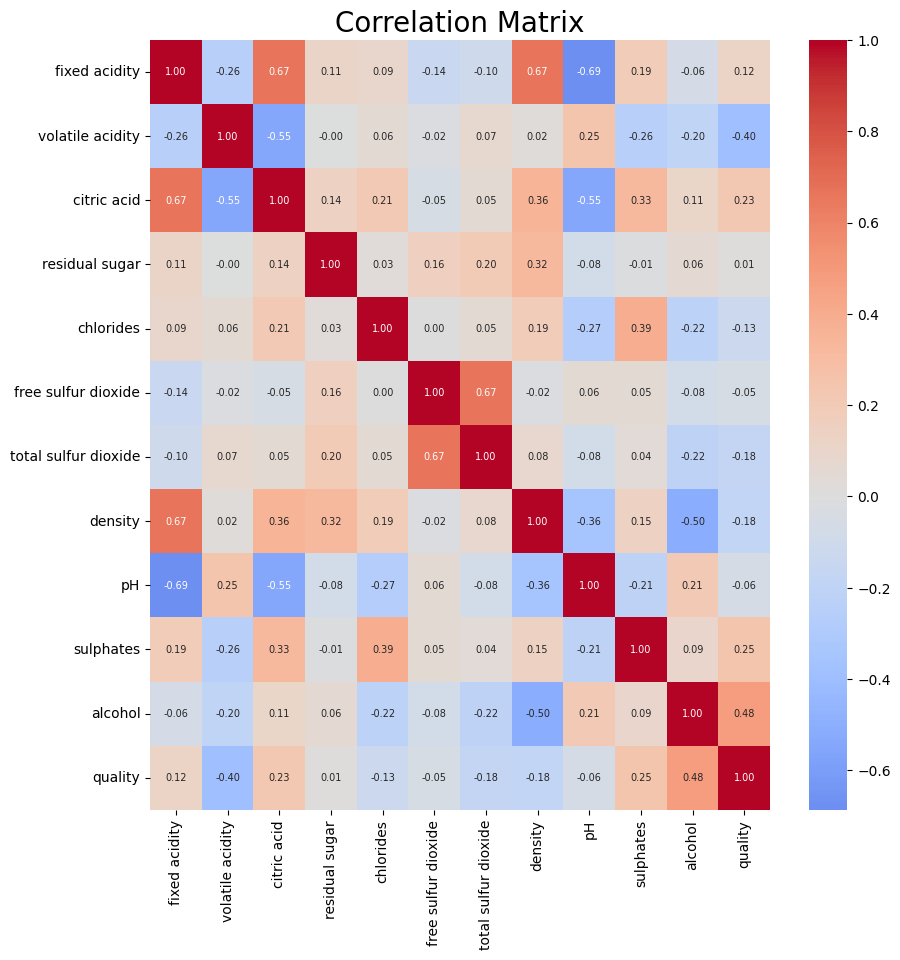

In [22]:
plt.figure(figsize=(10,10))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm',
            fmt=".2f", center=0, annot_kws={"size":7})
plt.title('Correlation Matrix', fontsize=20)
plt.show()

**Interpretasi:**


Berikut adalah interpretasi sederhana untuk bagian **target (`quality`)** berdasarkan matriks korelasi di atas:

Korelasi Positif Terkuat dengan `quality`:
* **`alcohol` (0.48)**: Memiliki hubungan positif yang paling kuat. Artinya, semakin tinggi kadar alkohol dalam anggur, cenderung semakin tinggi pula tingkat kualitas (`quality`) yang diberikan.
* **`sulphates` (0.25)** dan **`citric acid` (0.23)** juga menunjukkan hubungan positif yang moderat terhadap kualitas.

Korelasi Negatif Terkuat dengan `quality`:
* **`volatile acidity` (-0.40)**: Memiliki hubungan negatif yang paling signifikan. Artinya, semakin tinggi kadar asam volatil (asam menguap), maka kualitas anggur cenderung semakin menurun.
* Faktor lain seperti **`density` (-0.18)**, **`total sulfur dioxide` (-0.18)**, dan **`chlorides` (-0.13)** menunjukkan korelasi negatif yang lemah terhadap kualitas.


Korelasi Lemah/Hampir Tidak Berhubungan:

* **`residual sugar` (0.01)** dan **`pH` (-0.06)** memiliki angka korelasi yang sangat mendekati nol, yang mengindikasikan bahwa kedua variabel ini hampir tidak memiliki hubungan linear yang berarti terhadap penilaian kualitas anggur dalam dataset ini.

### b) Running PCA & Explained Variance Ratio

Saya jalankan PCA penuh dulu untuk melihat berapa banyak variansi yang ditangkap tiap komponen.

In [26]:
pca_full = PCA()
pca_full.fit(X_std)

evr = pca_full.explained_variance_ratio_

for i, ev in enumerate(evr, start=1):
    print(f"PC{i:2d}: {ev*100:5.2f}% variansi  (kumulatif {evr[:i].sum()*100:5.2f}%)")

PC 1: 28.29% variansi  (kumulatif 28.29%)
PC 2: 17.35% variansi  (kumulatif 45.64%)
PC 3: 14.07% variansi  (kumulatif 59.71%)
PC 4: 11.37% variansi  (kumulatif 71.08%)
PC 5:  8.74% variansi  (kumulatif 79.81%)
PC 6:  5.80% variansi  (kumulatif 85.61%)
PC 7:  5.34% variansi  (kumulatif 90.94%)
PC 8:  3.75% variansi  (kumulatif 94.69%)
PC 9:  3.13% variansi  (kumulatif 97.82%)
PC10:  1.65% variansi  (kumulatif 99.46%)
PC11:  0.54% variansi  (kumulatif 100.00%)


**Interpretasi:**

Berikut adalah interpretasi sederhana dari data *Principal Component Analysis* (PCA) di atas:

* **Informasi Utama (PC 1):** Komponen utama pertama (`PC 1`) menyimpan informasi atau keragaman (variansi) paling besar dibanding yang lain, yaitu **28,29%**.

* **Akumulasi Penjelasan Data (Kumulatif):**
  * Jika Anda menggunakan **4 komponen pertama (PC 1 sampai PC 4)**, Anda sudah bisa merangkum **71,08%** dari total informasi keseluruhan data asli.
  * Jika ingin mempertahankan sebagian besar informasi (misalnya sekitar **90%**), Anda dapat menggunakan **7 komponen pertama (`PC 1` sampai `PC 7`)** yang memiliki total variansi kumulatif sebesar **90,94%**.


* **Penyederhanaan Dimensi (Reduksi):** Dari 11 variabel awal, Anda bisa mereduksinya menjadi jauh lebih sedikit (misalnya 4 hingga 7 variabel baru) tanpa kehilangan terlalu banyak informasi penting dari data Anda.


In [35]:
cum = np.cumsum(evr)

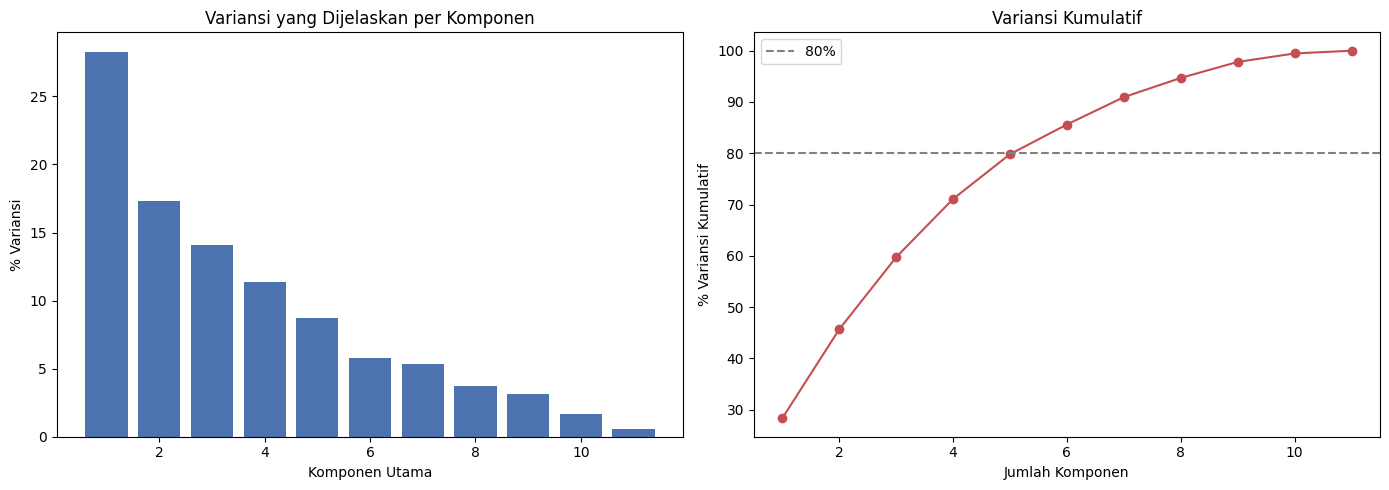

In [37]:
fig, ax = plt.subplots(1,2, figsize=(14,5))

ax[0].bar(range(1, len(evr)+1), evr*100, color="#4C72B0")
ax[0].set_title("Variansi yang Dijelaskan per Komponen")
ax[0].set_xlabel("Komponen Utama")
ax[0].set_ylabel("% Variansi")

ax[1].plot(range(1, len(cum)+1), cum*100, "o-", color="#C44E52")
ax[1].axhline(80, color="gray", linestyle="--", label="80%")
ax[1].set_title("Variansi Kumulatif")
ax[1].set_xlabel("Jumlah Komponen"); ax[1].set_ylabel("% Variansi Kumulatif")
ax[1].legend()
plt.tight_layout()
plt.show()

**Interpretasi:**


Berikut adalah interpretasi sederhana untuk kedua grafik PCA (Principal Component Analysis) tersebut:

### 1. Grafik Kiri: "Variansi yang Dijelaskan per Komponen" (Bar Chart)

* **Menunjukkan kontribusi masing-masing komponen**: Grafik ini menampilkan seberapa besar persentase informasi atau keragaman data yang disumbangkan oleh setiap komponen utama secara terpisah.
**Komponen paling berpengaruh**:
  * **Komponen 1 (PC 1)** memberikan sumbangan informasi paling tinggi, yaitu sekitar **28%**.
  * Semakin ke kanan (dari komponen 2 ke komponen 11), batang grafiknya semakin pendek, yang berarti kontribusi informasinya semakin kecil terhadap keseluruhan data.



### 2. Grafik Kanan: "Variansi Kumulatif" (Line Chart)

* **Menunjukkan akumulasi total informasi**: Grafik garis ini menghitung total gabungan persentase informasi dari komponen pertama hingga komponen ke-n secara bertahap.


* **Panduan Garis Batas (80%):**
  * Garis putus-putus horizontal menunjukkan batas target umum sebesar **80%**.
  * Titik merah menunjukkan persentase kumulatif; dapat dilihat bahwa untuk mencapai garis batas 80% (atau tepatnya menyentuh angka sekitar 80%), Anda membutuhkan tepat **5 komponen utama**.


---

**Kesimpulan Praktis:**
Jika Anda ingin meringkas data dari 11 fitur asli tanpa kehilangan banyak informasi (mempertahankan setidaknya 80% informasi), Anda cukup menggunakan **5 komponen utama pertama** berdasarkan grafik kumulatif di sebelah kanan.

## Conclusion & Insight

**Conclusion & Insight:**

1. **Reduksi Dimensi yang Efektif**:
   - Dengan menggunakan PCA, kita dapat mereduksi dataset yang awalnya memiliki **11 fitur kimiawi** menjadi hanya **5 komponen utama** saja, namun tetap berhasil mempertahankan hampir **80% (79.81%)** informasi atau variansi dari keseluruhan data asli.
   - Ini sangat berguna untuk menyederhanakan data sebelum dimasukkan ke dalam model machine learning guna menghindari *curse of dimensionality* dan mempercepat waktu komputasi.

2. **Korelasi & Kontribusi Fitur**:
   - Berdasarkan matriks korelasi awal, kadar `alcohol` memiliki hubungan positif paling kuat terhadap kualitas anggur, sedangkan `volatile acidity` memiliki hubungan negatif paling kuat.
   - Komponen Utama Pertama (PC1) memegang peranan paling krusial dengan merangkum **28.29%** informasi sendirian.

3. **Rekomendasi Langkah Selanjutnya**:
   - Kita dapat mentransformasikan data asli ke dalam ruang PCA berdimensi 2 (PC1 & PC2) untuk memvisualisasikan sebaran kelas kualitas anggur secara 2D.
   - Fitur baru hasil PCA ini (PC1 sampai PC5) dapat langsung digunakan sebagai input untuk model klasifikasi atau regresi guna menguji performanya dibanding menggunakan seluruh 11 fitur asli.


